<a href="https://colab.research.google.com/github/nileve-teo/INSTRUMENTACION-BIOMEDICA/blob/main/Cuestionario4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

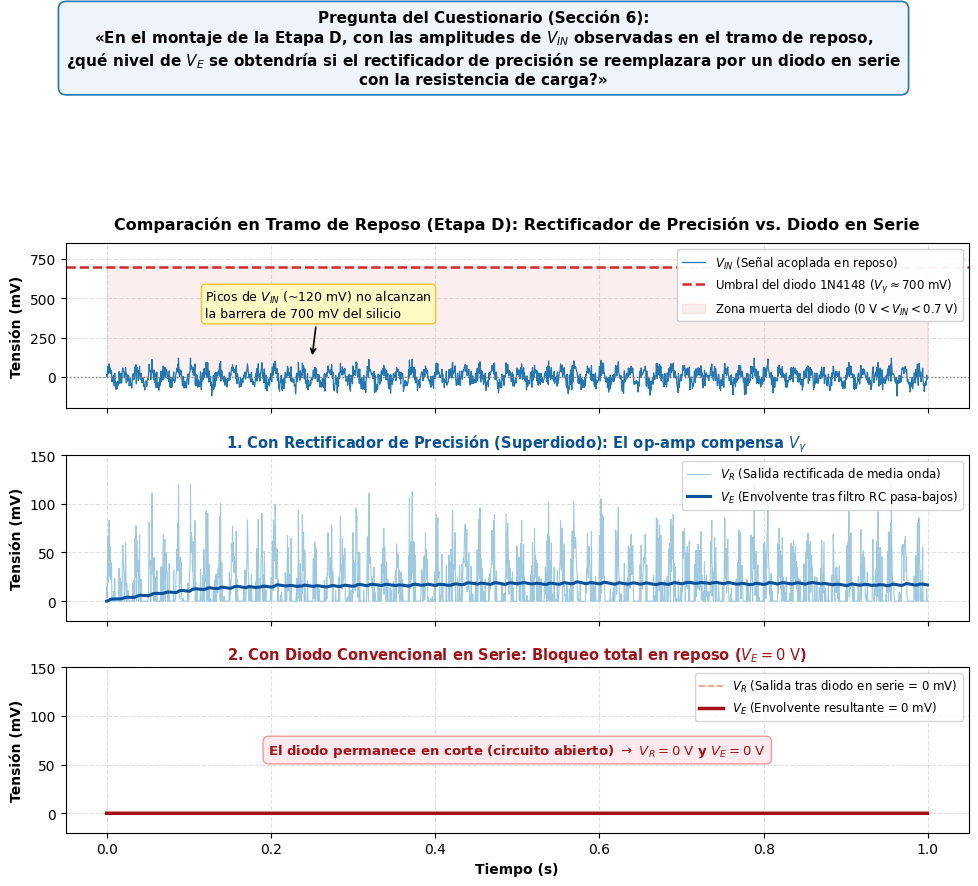

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

# 1. Parámetros de simulación (Tramo de Reposo - Etapa D)
fs = 2048                   # Frecuencia de muestreo del ESP32 (Hz)
duracion = 1.0              # Segundos a visualizar
t = np.linspace(0, duracion, int(fs * duracion), endpoint=False)

# Señal VIN en reposo (acoplada en AC, centrada en 0 V, amplitud ~80 mV pico)
np.random.seed(42)
ruido_reposo = 0.03 * np.random.randn(len(t)) + 0.04 * np.sin(2 * np.pi * 60 * t)
# Limitamos picos máximos alrededor de ±0.12 V (muy por debajo de 0.7 V)
v_in = np.clip(ruido_reposo, -0.12, 0.12)

# 2. Procesamiento: Rectificador de precisión vs. Diodo convencional
v_gamma = 0.7   # Umbral de conducción del diodo 1N4148 (V)

# A) Rectificador de precisión (Superdiodo): V_R = max(0, V_IN)
v_r_precision = np.maximum(0, v_in)

# B) Diodo convencional en serie: V_R = max(0, V_IN - 0.7 V)
v_r_diodo = np.maximum(0, v_in - v_gamma)

# 3. Filtro pasa-bajos RC (fc ≈ 1.59 Hz para R=10k, C=10uF) para obtener VE
fc = 1 / (2 * np.pi * 10e3 * 10e-6)
b, a = butter(1, fc / (fs / 2), btype='low')

# Simulamos la carga gradual del capacitor RC desde 0 V
v_e_precision = lfilter(b, a, v_r_precision)
v_e_diodo = lfilter(b, a, v_r_diodo)

# 4. Generación de la gráfica explicativa (dpi=100 en pantalla para evitar parpadeo)
plt.rcParams['font.family'] = 'sans-serif'
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, dpi=100)
fig.patch.set_facecolor('white')

# Título superior con la pregunta exacta del cuestionario
pregunta = (
    "Pregunta del Cuestionario (Sección 6):\n"
    "«En el montaje de la Etapa D, con las amplitudes de $V_{IN}$ observadas en el tramo de reposo,\n"
    "¿qué nivel de $V_E$ se obtendría si el rectificador de precisión se reemplazara por un diodo en serie\n"
    "con la resistencia de carga?»"
)
fig.suptitle(pregunta, fontsize=11, fontweight='bold', y=0.98,
             bbox=dict(boxstyle='round,pad=0.5', fc='#eef4fa', ec='#1f77b4', lw=1.2))

# --- Subgráfica 1: Señal de entrada VIN vs Umbral del Diodo ---
axes[0].plot(t, v_in * 1000, color='#1f77b4', linewidth=0.9, label='$V_{IN}$ (Señal acoplada en reposo)')
axes[0].axhline(v_gamma * 1000, color='#d62728', linestyle='--', linewidth=1.8, label='Umbral del diodo 1N4148 ($V_\\gamma \\approx 700\\text{ mV}$)')
axes[0].axhline(0, color='gray', linestyle=':', linewidth=1)
axes[0].fill_between(t, 0, v_gamma * 1000, color='#d62728', alpha=0.08, label='Zona muerta del diodo ($0\\text{ V} < V_{IN} < 0.7\\text{ V}$)')
axes[0].set_ylabel('Tensión (mV)', fontsize=10, fontweight='bold')
axes[0].set_title('Comparación en Tramo de Reposo (Etapa D): Rectificador de Precisión vs. Diodo en Serie', fontsize=11.5, fontweight='bold', pad=10)
axes[0].set_ylim(-200, 850)
axes[0].legend(loc='upper right', fontsize=8.5, framealpha=0.95)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Anotación movida hacia la izquierda para que no choque con la leyenda
axes[0].annotate('Picos de $V_{IN}$ (~120 mV) no alcanzan\nla barrera de 700 mV del silicio',
                 xy=(0.25, 120), xytext=(0.12, 380),
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
                 fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='#fff9c4', ec='#fbc02d'))

# --- Subgráfica 2: Salida con Rectificador de Precisión (TL084 + 1N4148) ---
axes[1].plot(t, v_r_precision * 1000, color='#9ecae1', linewidth=0.8, label='$V_R$ (Salida rectificada de media onda)')
axes[1].plot(t, v_e_precision * 1000, color='#08519c', linewidth=2.2, label='$V_E$ (Envolvente tras filtro RC pasa-bajos)')
axes[1].set_ylabel('Tensión (mV)', fontsize=10, fontweight='bold')
axes[1].set_title('1. Con Rectificador de Precisión (Superdiodo): El op-amp compensa $V_\\gamma$', fontsize=10.5, fontweight='bold', color='#08519c')
axes[1].set_ylim(-20, 150)
axes[1].legend(loc='upper right', fontsize=8.5)
axes[1].grid(True, linestyle='--', alpha=0.4)

# --- Subgráfica 3: Salida con Diodo Convencional en Serie ---
axes[2].plot(t, v_r_diodo * 1000, color='#fc9272', linewidth=1.2, linestyle='--', label='$V_R$ (Salida tras diodo en serie = 0 mV)')
axes[2].plot(t, v_e_diodo * 1000, color='#a50f15', linewidth=2.5, label='$V_E$ (Envolvente resultante = 0 mV)')
axes[2].set_ylabel('Tensión (mV)', fontsize=10, fontweight='bold')
axes[2].set_xlabel('Tiempo (s)', fontsize=10, fontweight='bold')
axes[2].set_title('2. Con Diodo Convencional en Serie: Bloqueo total en reposo ($V_E = 0\\text{ V}$)', fontsize=10.5, fontweight='bold', color='#a50f15')
axes[2].set_ylim(-20, 150)
axes[2].legend(loc='upper right', fontsize=8.5)
axes[2].grid(True, linestyle='--', alpha=0.4)
axes[2].text(0.5, 65, 'El diodo permanece en corte (circuito abierto) $\\rightarrow$ $V_R = 0\\text{ V}$ y $V_E = 0\\text{ V}$',
             ha='center', va='center', fontsize=9.5, fontweight='bold', color='#a50f15',
             bbox=dict(boxstyle='round,pad=0.4', fc='#ffebee', ec='#ef9a9a'))

plt.tight_layout(rect=[0, 0, 1, 0.87])
plt.savefig('comparacion_diodo_reposo.png', dpi=300, bbox_inches='tight')
plt.show()

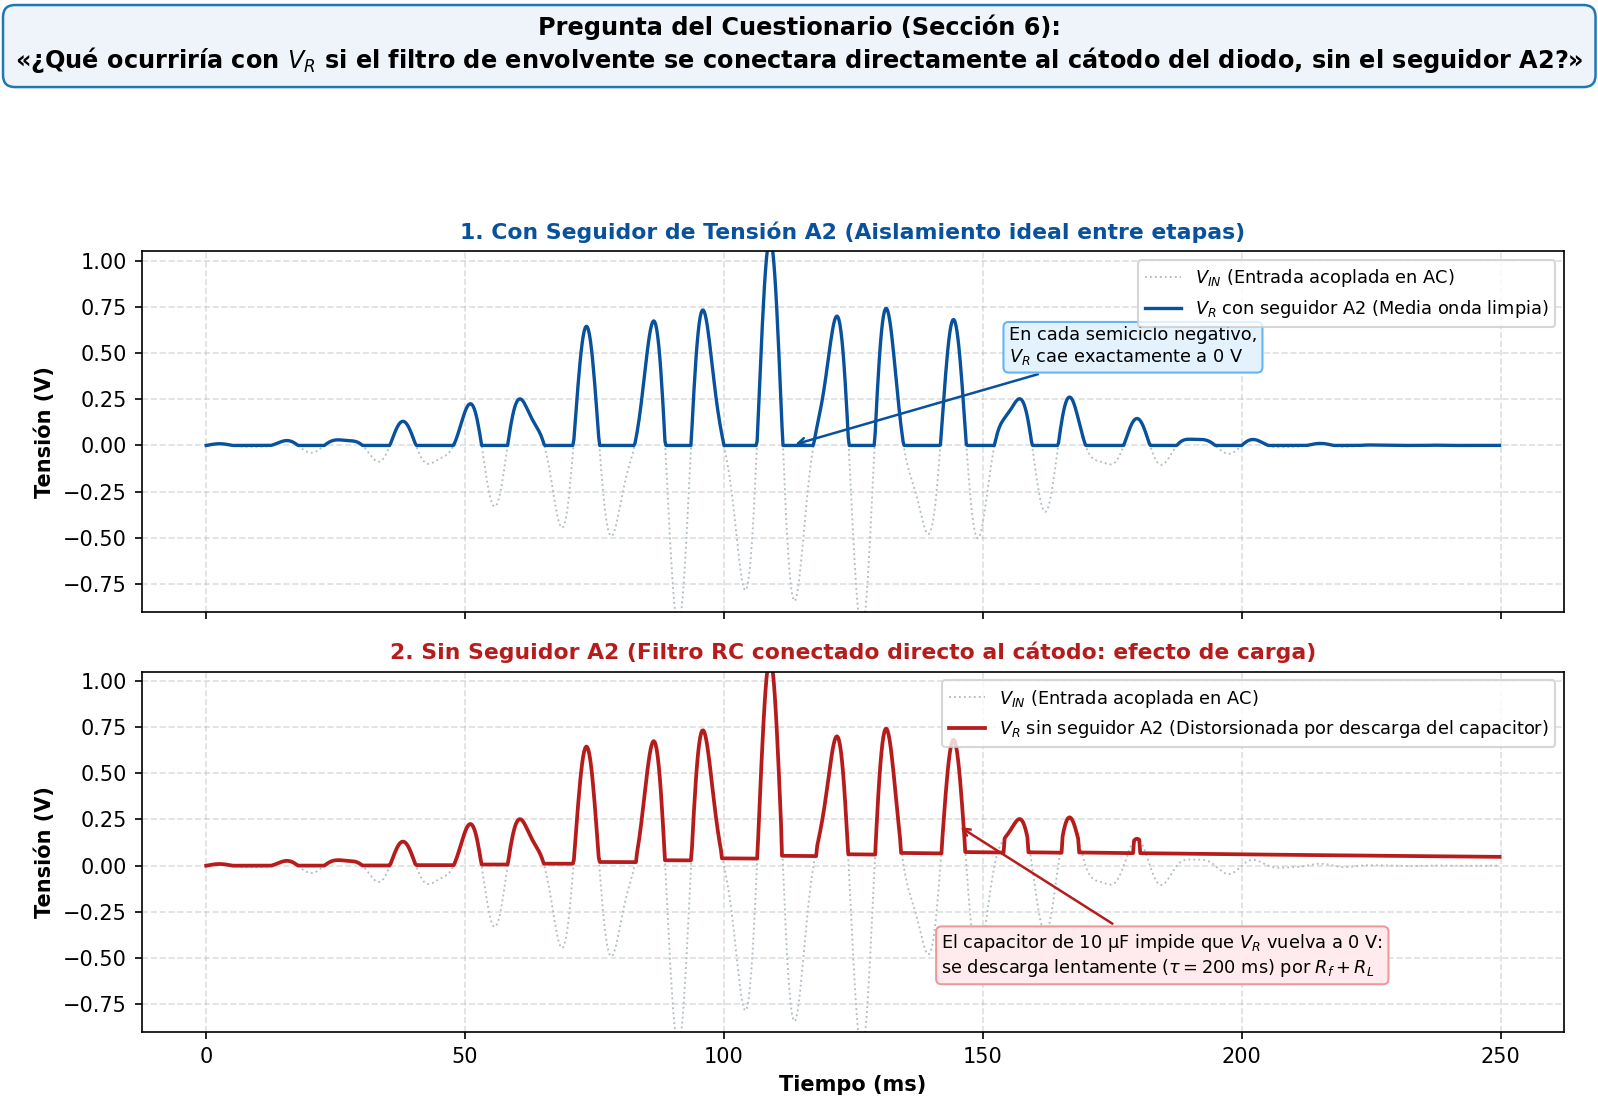

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros de simulación (ráfaga sEMG simulada)
fs = 5000                  # Frecuencia de muestreo (Hz)
duracion = 0.25            # 250 ms para apreciar tanto ciclos rápidos como la descarga RC
t = np.linspace(0, duracion, int(fs * duracion), endpoint=False)

# Señal VIN (burst de actividad muscular acoplada en AC)
envolvente_real = 0.8 * np.exp(-((t - 0.11) ** 2) / (2 * 0.035 ** 2))
np.random.seed(7)
portadora = np.sin(2 * np.pi * 85 * t) + 0.4 * np.sin(2 * np.pi * 140 * t)
v_in = envolvente_real * portadora

# 2. Caso A: VR CON seguidor de tensión A2 (Aislamiento de impedancias)
# El rectificador ve únicamente su resistencia de carga R_L = 10k hacia GND.
# Durante V_IN < 0, el diodo abre y R_L lleva VR instantáneamente a 0 V.
v_r_con_seguidor = np.maximum(0, v_in)

# 3. Caso B: VR SIN seguidor de tensión A2 (Filtro RC conectado directo al cátodo)
# Valores del circuito: R_L = 10 kΩ (carga del rectificador), R_f = 10 kΩ, C_f = 10 µF
R_L = 10e3
R_f = 10e3
C_f = 10e-6
dt = 1 / fs

v_r_sin_seguidor = np.zeros_like(v_in)
v_cap = 0.0  # Tensión inicial en el condensador de 10 µF

for i in range(1, len(t)):
    if v_in[i] > v_cap:
        # Diodo en directa: el op-amp A1 impone V_R = V_IN
        v_r_sin_seguidor[i] = v_in[i]
        # El condensador se carga a través de R_f
        i_carga = (v_r_sin_seguidor[i] - v_cap) / R_f
        v_cap += (i_carga / C_f) * dt
    else:
        # Diodo en inversa (abierto): el condensador se descarga lentamente
        # a través de (R_f + R_L) = 20 kΩ, manteniendo VR > 0 V por divisor resistivo
        i_descarga = v_cap / (R_f + R_L)
        v_cap -= (i_descarga / C_f) * dt
        v_r_sin_seguidor[i] = v_cap * (R_L / (R_f + R_L))

# 4. Generación de la figura con la pregunta incluida
plt.rcParams['font.family'] = 'sans-serif'
fig, axes = plt.subplots(2, 1, figsize=(10.5, 7.5), sharex=True, dpi=150)
fig.patch.set_facecolor('white')

# Título superior con la pregunta exacta del cuestionario
pregunta = (
    "Pregunta del Cuestionario (Sección 6):\n"
    "«¿Qué ocurriría con $V_R$ si el filtro de envolvente se conectara directamente "
    "al cátodo del diodo, sin el seguidor A2?»"
)
fig.suptitle(pregunta, fontsize=11.5, fontweight='bold', y=0.98,
             bbox=dict(boxstyle='round,pad=0.5', fc='#eef4fa', ec='#1f77b4', lw=1.2))

# --- Subgráfica 1: Con seguidor A2 (Configuración original) ---
axes[0].plot(t * 1000, v_in, color='#b0bec5', linewidth=0.9, linestyle=':', label='$V_{IN}$ (Entrada acoplada en AC)')
axes[0].plot(t * 1000, v_r_con_seguidor, color='#08519c', linewidth=1.6, label='$V_R$ con seguidor A2 (Media onda limpia)')
axes[0].set_ylabel('Tensión (V)', fontsize=10, fontweight='bold')
axes[0].set_title('1. Con Seguidor de Tensión A2 (Aislamiento ideal entre etapas)', fontsize=10.5, fontweight='bold', color='#08519c')
axes[0].set_ylim(-0.9, 1.05)
axes[0].legend(loc='upper right', fontsize=8.5)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].annotate('En cada semiciclo negativo,\n$V_R$ cae exactamente a 0 V',
                 xy=(113, 0.0), xytext=(155, 0.45),
                 arrowprops=dict(arrowstyle='->', color='#08519c', lw=1.2),
                 fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#e3f2fd', ec='#64b5f6'))

# --- Subgráfica 2: Sin seguidor A2 (Efecto de carga del filtro RC) ---
axes[1].plot(t * 1000, v_in, color='#b0bec5', linewidth=0.9, linestyle=':', label='$V_{IN}$ (Entrada acoplada en AC)')
axes[1].plot(t * 1000, v_r_sin_seguidor, color='#b71c1c', linewidth=1.8, label='$V_R$ sin seguidor A2 (Distorsionada por descarga del capacitor)')
axes[1].set_ylabel('Tensión (V)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Tiempo (ms)', fontsize=10, fontweight='bold')
axes[1].set_title('2. Sin Seguidor A2 (Filtro RC conectado directo al cátodo: efecto de carga)', fontsize=10.5, fontweight='bold', color='#b71c1c')
axes[1].set_ylim(-0.9, 1.05)
axes[1].legend(loc='upper right', fontsize=8.5)
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].annotate('El capacitor de 10 µF impide que $V_R$ vuelva a 0 V:\nse descarga lentamente ($\\tau = 200\\text{ ms}$) por $R_f + R_L$',
                 xy=(145, 0.22), xytext=(142, -0.58),
                 arrowprops=dict(arrowstyle='->', color='#b71c1c', lw=1.2),
                 fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#ffebee', ec='#ef9a9a'))

plt.tight_layout(rect=[0, 0, 1, 0.89])
plt.savefig('efecto_sin_seguidor_A2.png', dpi=300, bbox_inches='tight')
plt.show()

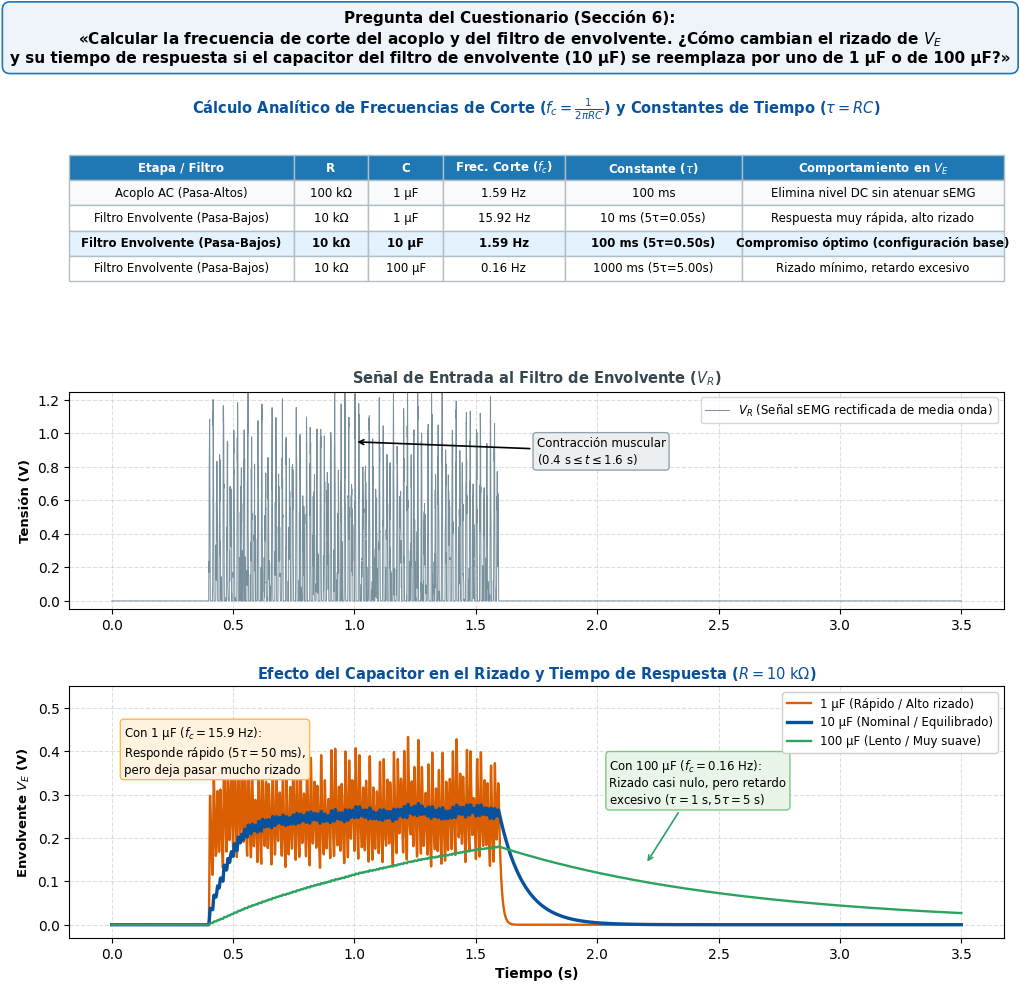

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

# ==============================================================================
# 1. PARÁMETROS DEL CIRCUITO (ETAPA D) Y CÁLCULOS ANALÍTICOS
# ==============================================================================
R_ac = 100e3        # 100 kΩ (Acoplo AC)
C_ac = 1e-6         # 1 µF
fc_acoplo = 1 / (2 * np.pi * R_ac * C_ac)

R_env = 10e3        # 10 kΩ (Filtro de envolvente)
capacitores = [1e-6, 10e-6, 100e-6]
etiquetas = ['1 µF (Rápido / Alto rizado)', '10 µF (Nominal / Equilibrado)', '100 µF (Lento / Muy suave)']
colores = ['#d95f02', '#08519c', '#2ca25f']

# Preparamos los datos formateados para la tabla integrada
filas_tabla = [
    ['Acoplo AC (Pasa-Altos)', '100 kΩ', '1 µF', f'{fc_acoplo:.2f} Hz', '100 ms', 'Elimina nivel DC sin atenuar sEMG'],
]
descripciones = [
    'Respuesta muy rápida, alto rizado',
    'Compromiso óptimo (configuración base)',
    'Rizado mínimo, retardo excesivo'
]
for C, desc in zip(capacitores, descripciones):
    fc = 1 / (2 * np.pi * R_env * C)
    tau = R_env * C
    filas_tabla.append([
        'Filtro Envolvente (Pasa-Bajos)',
        '10 kΩ',
        f'{C*1e6:.0f} µF',
        f'{fc:.2f} Hz',
        f'{tau*1e3:.0f} ms (5τ={5*tau:.2f}s)',
        desc
    ])

# ==============================================================================
# 2. SIMULACIÓN DE LA SEÑAL sEMG RECTIFICADA (VR) Y ENVOLVENTES (VE)
# ==============================================================================
fs = 2000
duracion = 3.5
t = np.linspace(0, duracion, int(fs * duracion), endpoint=False)

pulso = np.where((t >= 0.4) & (t <= 1.6), 1.0, 0.0)
np.random.seed(15)
portadora_emg = 0.75 * np.sin(2 * np.pi * 70 * t) + 0.35 * np.sin(2 * np.pi * 120 * t) + 0.15 * np.random.randn(len(t))
v_in = pulso * portadora_emg
v_r = np.maximum(0, v_in)

envolventes = []
for C in capacitores:
    fc = 1 / (2 * np.pi * R_env * C)
    b, a = butter(1, fc / (fs / 2), btype='low')
    envolventes.append(lfilter(b, a, v_r))

# ==============================================================================
# 3. FIGURA UNIFICADA (PREGUNTA + TABLA DE CÁLCULOS + GRÁFICAS)
# ==============================================================================
plt.rcParams['font.family'] = 'sans-serif'
fig = plt.figure(figsize=(10.5, 10.2), dpi=100)
fig.patch.set_facecolor('white')

# Cuadrícula con 3 filas: [0] Tabla de cálculos, [1] Gráfica VR, [2] Gráfica VE
gs = fig.add_gridspec(3, 1, height_ratios=[1.15, 1.3, 1.5], hspace=0.35)

# Título superior con la pregunta exacta
pregunta = (
    "Pregunta del Cuestionario (Sección 6):\n"
    "«Calcular la frecuencia de corte del acoplo y del filtro de envolvente. ¿Cómo cambian el rizado de $V_E$\n"
    "y su tiempo de respuesta si el capacitor del filtro de envolvente (10 µF) se reemplaza por uno de 1 µF o de 100 µF?»"
)
fig.suptitle(pregunta, fontsize=11, fontweight='bold', y=0.97,
             bbox=dict(boxstyle='round,pad=0.5', fc='#eef4fa', ec='#1f77b4', lw=1.2))

# --- Sección 0: Tabla Estilizada con los Cálculos ---
ax_tabla = fig.add_subplot(gs[0])
ax_tabla.axis('off')
ax_tabla.set_title('Cálculo Analítico de Frecuencias de Corte ($f_c = \\frac{1}{2\\pi R C}$) y Constantes de Tiempo ($\\tau = RC$)',
                   fontsize=10.5, fontweight='bold', color='#08519c', pad=6)

columnas = ['Etapa / Filtro', 'R', 'C', 'Frec. Corte ($f_c$)', 'Constante ($\\tau$)', 'Comportamiento en $V_E$']
tabla = ax_tabla.table(
    cellText=filas_tabla,
    colLabels=columnas,
    loc='center',
    cellLoc='center',
    colWidths=[0.24, 0.08, 0.08, 0.13, 0.19, 0.28]
)
tabla.auto_set_font_size(False)
tabla.set_fontsize(8.5)
tabla.scale(1, 1.45)

# Estilizar celdas (encabezados azules y fila nominal resaltada)
for (row, col), cell in tabla.get_celld().items():
    cell.set_edgecolor('#b0bec5')
    if row == 0:
        cell.set_facecolor('#1f77b4')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    elif row == 3:  # Fila nominal de 10 µF
        cell.set_facecolor('#e3f2fd')
        cell.get_text().set_weight('bold')
    elif row % 2 == 1:
        cell.set_facecolor('#f8fafc')
    else:
        cell.set_facecolor('white')

# --- Sección 1: Señal rectificada VR ---
ax1 = fig.add_subplot(gs[1])
ax1.plot(t, v_r, color='#78909c', linewidth=0.7, label='$V_R$ (Señal sEMG rectificada de media onda)')
ax1.set_ylabel('Tensión (V)', fontsize=9.5, fontweight='bold')
ax1.set_title('Señal de Entrada al Filtro de Envolvente ($V_R$)', fontsize=10.5, fontweight='bold', color='#37474f', pad=6)
ax1.set_ylim(-0.05, 1.25)
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.annotate('Contracción muscular\n($0.4\\text{ s} \\leq t \\leq 1.6\\text{ s}$)',
             xy=(1.0, 0.95), xytext=(1.75, 0.82),
             arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#eceff1', ec='#90a4ae'))

# --- Sección 2: Comparación de VE para 1 µF, 10 µF y 100 µF ---
ax2 = fig.add_subplot(gs[2], sharex=ax1)
for v_e, label, color in zip(envolventes, etiquetas, colores):
    lw = 2.4 if '10 µF' in label else 1.7
    ax2.plot(t, v_e, color=color, linewidth=lw, label=label)

ax2.set_ylabel('Envolvente $V_E$ (V)', fontsize=9.5, fontweight='bold')
ax2.set_xlabel('Tiempo (s)', fontsize=10, fontweight='bold')
ax2.set_title('Efecto del Capacitor en el Rizado y Tiempo de Respuesta ($R = 10\\text{ k}\\Omega$)',
              fontsize=10.5, fontweight='bold', color='#08519c', pad=6)
ax2.set_ylim(-0.03, 0.55)
ax2.legend(loc='upper right', fontsize=8.5, framealpha=0.95)
ax2.grid(True, linestyle='--', alpha=0.4)

ax2.annotate('Con 1 µF ($f_c = 15.9\\text{ Hz}$):\nResponde rápido ($5\\tau = 50\\text{ ms}$),\npero deja pasar mucho rizado',
             xy=(0.75, 0.42), xytext=(0.05, 0.35),
             arrowprops=dict(arrowstyle='->', color='#d95f02', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#fff3e0', ec='#ffb74d'))

ax2.annotate('Con 100 µF ($f_c = 0.16\\text{ Hz}$):\nRizado casi nulo, pero retardo\nexcesivo ($\\tau = 1\\text{ s}, 5\\tau = 5\\text{ s}$)',
             xy=(2.2, 0.14), xytext=(2.05, 0.28),
             arrowprops=dict(arrowstyle='->', color='#2ca25f', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#e8f5e9', ec='#81c784'))

plt.subplots_adjust(top=0.86, bottom=0.06, left=0.08, right=0.97)
plt.savefig('comparacion_capacitores_envolvente.png', dpi=300, bbox_inches='tight')
plt.show()

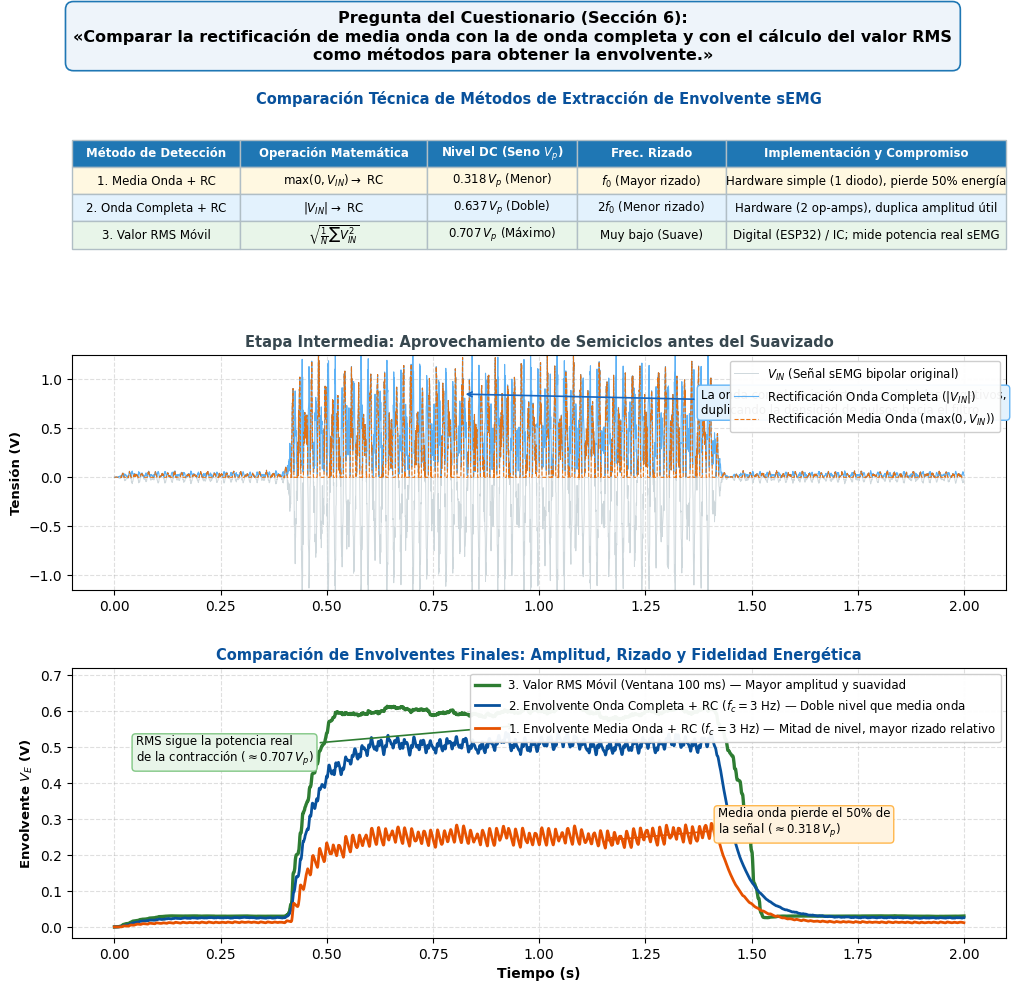

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

# ==============================================================================
# 1. SIMULACIÓN DE LA SEÑAL sEMG DE ENTRADA (VIN) Y LOS 3 MÉTODOS DE ENVOLVENTE
# ==============================================================================
fs = 2000                   # Frecuencia de muestreo (Hz)
duracion = 2.0              # Segundos
t = np.linspace(0, duracion, int(fs * duracion), endpoint=False)

# Simulamos una contracción muscular (ráfaga sEMG) entre t = 0.4 s y t = 1.4 s
envolvente_muscular = np.where((t >= 0.4) & (t <= 1.4), 1.0, 0.05)
# Suavizamos ligeramente los bordes de la contracción para realismo fisiológico
b_env, a_env = butter(2, 15 / (fs / 2), btype='low')
perfil_contraccion = lfilter(b_env, a_env, envolvente_muscular)

np.random.seed(24)
portadora_emg = 0.75 * np.sin(2 * np.pi * 65 * t) + 0.35 * np.sin(2 * np.pi * 115 * t) + 0.15 * np.random.randn(len(t))
v_in = perfil_contraccion * portadora_emg

# Filtro pasa-bajos RC equivalente (fc = 3 Hz para visualizar bien la diferencia de rizado)
fc_env = 3.0
b_rc, a_rc = butter(1, fc_env / (fs / 2), btype='low')

# MÉTODO 1: Rectificación de Media Onda + Filtro RC
v_rect_media = np.maximum(0, v_in)
env_media_onda = lfilter(b_rc, a_rc, v_rect_media)

# MÉTODO 2: Rectificación de Onda Completa + Filtro RC
v_rect_completa = np.abs(v_in)
env_onda_completa = lfilter(b_rc, a_rc, v_rect_completa)

# MÉTODO 3: Valor RMS Móvil (Ventana deslizante de 100 ms -> N = 200 muestras)
ventana_ms = 100
N_win = int((ventana_ms / 1000) * fs)
v_in_cuadrado = v_in ** 2
# Media móvil causal (equivalente a implementación en tiempo real en ESP32)
media_cuadratica = lfilter(np.ones(N_win) / N_win, 1, v_in_cuadrado)
env_rms = np.sqrt(np.maximum(0, media_cuadratica))

# ==============================================================================
# 2. TABLA COMPARATIVA DE LOS MÉTODOS
# ==============================================================================
columnas = ['Método de Detección', 'Operación Matemática', 'Nivel DC (Seno $V_p$)', 'Frec. Rizado', 'Implementación y Compromiso']
filas_tabla = [
    ['1. Media Onda + RC', '$\\max(0, V_{IN}) \\rightarrow$ RC', '$0.318\\,V_p$ (Menor)', '$f_0$ (Mayor rizado)', 'Hardware simple (1 diodo), pierde 50% energía'],
    ['2. Onda Completa + RC', '$|V_{IN}| \\rightarrow$ RC', '$0.637\\,V_p$ (Doble)', '$2f_0$ (Menor rizado)', 'Hardware (2 op-amps), duplica amplitud útil'],
    ['3. Valor RMS Móvil', '$\\sqrt{\\frac{1}{N}\\sum V_{IN}^2}$', '$0.707\\,V_p$ (Máximo)', 'Muy bajo (Suave)', 'Digital (ESP32) / IC; mide potencia real sEMG']
]

# ==============================================================================
# 3. FIGURA UNIFICADA (PREGUNTA + TABLA + GRÁFICAS)
# ==============================================================================
plt.rcParams['font.family'] = 'sans-serif'
fig = plt.figure(figsize=(10.5, 10.2), dpi=100)
fig.patch.set_facecolor('white')

gs = fig.add_gridspec(3, 1, height_ratios=[0.95, 1.35, 1.55], hspace=0.35)

# Título superior con la pregunta exacta
pregunta = (
    "Pregunta del Cuestionario (Sección 6):\n"
    "«Comparar la rectificación de media onda con la de onda completa y con el cálculo del valor RMS\n"
    "como métodos para obtener la envolvente.»"
)
fig.suptitle(pregunta, fontsize=11.5, fontweight='bold', y=0.97,
             bbox=dict(boxstyle='round,pad=0.5', fc='#eef4fa', ec='#1f77b4', lw=1.2))

# --- Sección 0: Tabla Estilizada ---
ax_tabla = fig.add_subplot(gs[0])
ax_tabla.axis('off')
ax_tabla.set_title('Comparación Técnica de Métodos de Extracción de Envolvente sEMG',
                   fontsize=10.5, fontweight='bold', color='#08519c', pad=6)

tabla = ax_tabla.table(
    cellText=filas_tabla,
    colLabels=columnas,
    loc='center',
    cellLoc='center',
    colWidths=[0.18, 0.20, 0.16, 0.16, 0.30]
)
tabla.auto_set_font_size(False)
tabla.set_fontsize(8.5)
tabla.scale(1, 1.55)

for (row, col), cell in tabla.get_celld().items():
    cell.set_edgecolor('#b0bec5')
    if row == 0:
        cell.set_facecolor('#1f77b4')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    elif row == 3:
        cell.set_facecolor('#e8f5e9')  # Destacar RMS
    elif row == 2:
        cell.set_facecolor('#e3f2fd')  # Destacar Onda completa
    else:
        cell.set_facecolor('#fff8e1')  # Destacar Media onda

# --- Sección 1: Señales Rectificadas (Media Onda vs Onda Completa) ---
ax1 = fig.add_subplot(gs[1])
ax1.plot(t, v_in, color='#cfd8dc', linewidth=0.7, label='$V_{IN}$ (Señal sEMG bipolar original)')
ax1.plot(t, v_rect_completa, color='#42a5f5', linewidth=0.8, alpha=0.85, label='Rectificación Onda Completa ($|V_{IN}|$)')
ax1.plot(t, v_rect_media, color='#ef6c00', linewidth=0.8, linestyle='--', alpha=0.9, label='Rectificación Media Onda ($\\max(0, V_{IN})$)')
ax1.set_ylabel('Tensión (V)', fontsize=9.5, fontweight='bold')
ax1.set_title('Etapa Intermedia: Aprovechamiento de Semiciclos antes del Suavizado',
              fontsize=10.5, fontweight='bold', color='#37474f', pad=6)
ax1.set_ylim(-1.15, 1.25)
ax1.legend(loc='upper right', fontsize=8.5, framealpha=0.95)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.annotate('La onda completa invierte los semiciclos negativos,\nduplicando la densidad de pulsos hacia el filtro',
             xy=(0.82, 0.85), xytext=(1.38, 0.65),
             arrowprops=dict(arrowstyle='->', color='#1565c0', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#e3f2fd', ec='#64b5f6'))

# --- Sección 2: Comparación de las 3 Envolventes Resultantes ---
ax2 = fig.add_subplot(gs[2], sharex=ax1)
ax2.plot(t, env_rms, color='#2e7d32', linewidth=2.4, label=f'3. Valor RMS Móvil (Ventana {ventana_ms} ms) — Mayor amplitud y suavidad')
ax2.plot(t, env_onda_completa, color='#08519c', linewidth=2.0, label='2. Envolvente Onda Completa + RC ($f_c = 3\\text{ Hz}$) — Doble nivel que media onda')
ax2.plot(t, env_media_onda, color='#e65100', linewidth=2.0, linestyle='-', label='1. Envolvente Media Onda + RC ($f_c = 3\\text{ Hz}$) — Mitad de nivel, mayor rizado relativo')

ax2.set_ylabel('Envolvente $V_E$ (V)', fontsize=9.5, fontweight='bold')
ax2.set_xlabel('Tiempo (s)', fontsize=10, fontweight='bold')
ax2.set_title('Comparación de Envolventes Finales: Amplitud, Rizado y Fidelidad Energética',
              fontsize=10.5, fontweight='bold', color='#08519c', pad=6)
ax2.set_ylim(-0.03, 0.72)
ax2.legend(loc='upper right', fontsize=8.5, framealpha=0.95)
ax2.grid(True, linestyle='--', alpha=0.4)

ax2.annotate('RMS sigue la potencia real\nde la contracción ($\\approx 0.707\\,V_p$)',
             xy=(0.95, 0.56), xytext=(0.05, 0.46),
             arrowprops=dict(arrowstyle='->', color='#2e7d32', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#e8f5e9', ec='#81c784'))

ax2.annotate('Media onda pierde el 50% de\nla señal ($\\approx 0.318\\,V_p$)',
             xy=(1.15, 0.24), xytext=(1.42, 0.26),
             arrowprops=dict(arrowstyle='->', color='#e65100', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#fff3e0', ec='#ffb74d'))

plt.subplots_adjust(top=0.87, bottom=0.06, left=0.08, right=0.97)
plt.savefig('comparacion_metodos_envolvente.png', dpi=300, bbox_inches='tight')
plt.show()

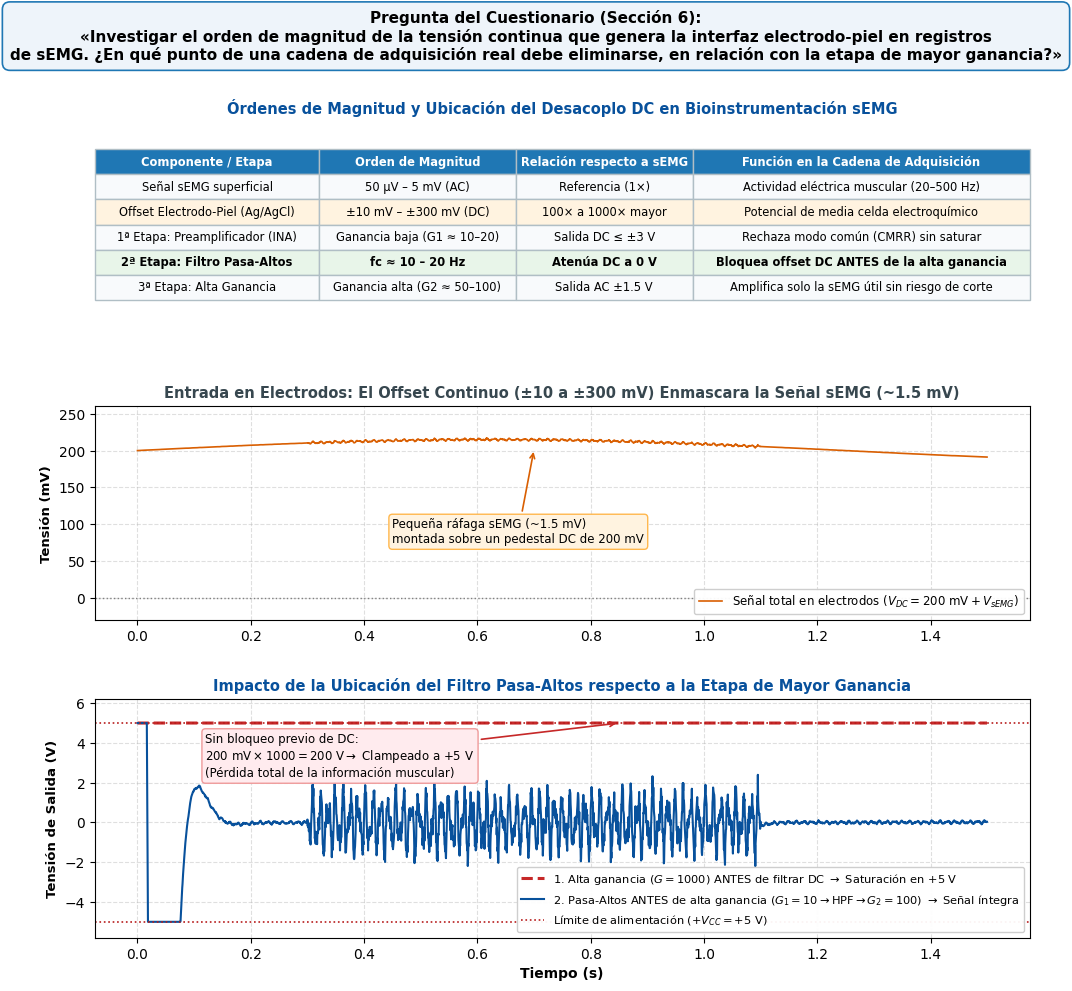

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

# ==============================================================================
# 1. SIMULACIÓN DE SEÑAL sEMG + OFFSET ELECTRODO-PIEL (200 mV DC)
# ==============================================================================
fs = 2000                   # Frecuencia de muestreo (Hz)
duracion = 1.5              # Segundos
t = np.linspace(0, duracion, int(fs * duracion), endpoint=False)

# Señal sEMG útil en piel: amplitud pico ~1.5 mV (0.0015 V)
pulso = np.where((t >= 0.3) & (t <= 1.1), 1.0, 0.05)
np.random.seed(10)
emg_cruda = pulso * 0.0015 * (0.7 * np.sin(2 * np.pi * 75 * t) + 0.4 * np.sin(2 * np.pi * 130 * t) + 0.2 * np.random.randn(len(t)))

# Potencial continuo de interfaz electrodo-piel: +200 mV (0.200 V) + leve deriva térmica
v_offset_dc = 0.200 + 0.015 * np.sin(2 * np.pi * 0.4 * t)
v_entrada_total = v_offset_dc + emg_cruda

# Rieles de alimentación típicos de etapa analógica (±5 V)
V_SAT = 5.0

# --- ESCENARIO A (INCORRECTO): Alta ganancia (G = 1000) ANTES de eliminar DC ---
G_total = 1000
v_sal_saturada = np.clip(v_entrada_total * G_total, -V_SAT, V_SAT)

# --- ESCENARIO B (CORRECTO): Preamplificación baja (G1=10) -> Pasa-Altos -> Alta Ganancia (G2=100) ---
G1 = 10
G2 = 100
v_preamp = v_entrada_total * G1  # 0.200 V * 10 = 2.0 V (no satura los ±5 V)

# Filtro pasa-altos de acoplamiento AC (fc = 10 Hz) para eliminar el offset DC
b_hp, a_hp = butter(2, 10 / (fs / 2), btype='high')
v_sin_dc = lfilter(b_hp, a_hp, v_preamp)

# Etapa de alta ganancia final (G2 = 100 -> Ganancia total = 1000)
v_sal_correcta = np.clip(v_sin_dc * G2, -V_SAT, V_SAT)

# ==============================================================================
# 2. TABLA TÉCNICA DE ÓRDENES DE MAGNITUD Y ARQUITECTURA
# ==============================================================================
columnas = ['Componente / Etapa', 'Orden de Magnitud', 'Relación respecto a sEMG', 'Función en la Cadena de Adquisición']
filas_tabla = [
    ['Señal sEMG superficial', '50 µV – 5 mV (AC)', 'Referencia (1×)', 'Actividad eléctrica muscular (20–500 Hz)'],
    ['Offset Electrodo-Piel (Ag/AgCl)', '±10 mV – ±300 mV (DC)', '100× a 1000× mayor', 'Potencial de media celda electroquímico'],
    ['1ª Etapa: Preamplificador (INA)', 'Ganancia baja (G1 ≈ 10–20)', 'Salida DC ≤ ±3 V', 'Rechaza modo común (CMRR) sin saturar'],
    ['2ª Etapa: Filtro Pasa-Altos', 'fc ≈ 10 – 20 Hz', 'Atenúa DC a 0 V', 'Bloquea offset DC ANTES de la alta ganancia'],
    ['3ª Etapa: Alta Ganancia', 'Ganancia alta (G2 ≈ 50–100)', 'Salida AC ±1.5 V', 'Amplifica solo la sEMG útil sin riesgo de corte']
]

# ==============================================================================
# 3. FIGURA UNIFICADA (PREGUNTA + TABLA + GRÁFICAS)
# ==============================================================================
plt.rcParams['font.family'] = 'sans-serif'
fig = plt.figure(figsize=(10.5, 10.2), dpi=100)
fig.patch.set_facecolor('white')

gs = fig.add_gridspec(3, 1, height_ratios=[1.25, 1.3, 1.45], hspace=0.36)

pregunta = (
    "Pregunta del Cuestionario (Sección 6):\n"
    "«Investigar el orden de magnitud de la tensión continua que genera la interfaz electrodo-piel en registros\n"
    "de sEMG. ¿En qué punto de una cadena de adquisición real debe eliminarse, en relación con la etapa de mayor ganancia?»"
)
fig.suptitle(pregunta, fontsize=11, fontweight='bold', y=0.97,
             bbox=dict(boxstyle='round,pad=0.5', fc='#eef4fa', ec='#1f77b4', lw=1.2))

# --- Sección 0: Tabla Estilizada ---
ax_tabla = fig.add_subplot(gs[0])
ax_tabla.axis('off')
ax_tabla.set_title('Órdenes de Magnitud y Ubicación del Desacoplo DC en Bioinstrumentación sEMG',
                   fontsize=10.5, fontweight='bold', color='#08519c', pad=6)

tabla = ax_tabla.table(
    cellText=filas_tabla,
    colLabels=columnas,
    loc='center',
    cellLoc='center',
    colWidths=[0.24, 0.21, 0.19, 0.36]
)
tabla.auto_set_font_size(False)
tabla.set_fontsize(8.3)
tabla.scale(1, 1.45)

for (row, col), cell in tabla.get_celld().items():
    cell.set_edgecolor('#b0bec5')
    if row == 0:
        cell.set_facecolor('#1f77b4')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    elif row == 2:
        cell.set_facecolor('#fff3e0')  # Resaltar Offset DC
    elif row == 4:
        cell.set_facecolor('#e8f5e9')  # Resaltar Filtro Pasa-Altos
        cell.get_text().set_weight('bold')
    elif row % 2 == 1:
        cell.set_facecolor('#f8fafc')
    else:
        cell.set_facecolor('white')

# --- Sección 1: Señal en Electrodos (Offset DC vs sEMG) ---
ax1 = fig.add_subplot(gs[1])
ax1.plot(t, v_entrada_total * 1000, color='#d95f02', linewidth=1.2, label='Señal total en electrodos ($V_{DC} = 200\\text{ mV} + V_{sEMG}$)')
ax1.axhline(0, color='gray', linestyle=':', linewidth=1)
ax1.set_ylabel('Tensión (mV)', fontsize=9.5, fontweight='bold')
ax1.set_title('Entrada en Electrodos: El Offset Continuo (±10 a ±300 mV) Enmascara la Señal sEMG (~1.5 mV)',
              fontsize=10.5, fontweight='bold', color='#37474f', pad=6)
ax1.set_ylim(-30, 260)
ax1.legend(loc='lower right', fontsize=8.5, framealpha=0.95)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.annotate('Pequeña ráfaga sEMG (~1.5 mV)\nmontada sobre un pedestal DC de 200 mV',
             xy=(0.7, 202), xytext=(0.45, 75),
             arrowprops=dict(arrowstyle='->', color='#d95f02', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#fff3e0', ec='#ffb74d'))

# --- Sección 2: Comparación de Salida (Saturación vs Eliminación Previa de DC) ---
ax2 = fig.add_subplot(gs[2], sharex=ax1)
ax2.plot(t, v_sal_saturada, color='#c62828', linewidth=2.2, linestyle='--', label='1. Alta ganancia ($G=1000$) ANTES de filtrar DC $\\rightarrow$ Saturación en $+5\\text{ V}$')
ax2.plot(t, v_sal_correcta, color='#08519c', linewidth=1.5, label='2. Pasa-Altos ANTES de alta ganancia ($G_1=10 \\rightarrow \\text{HPF} \\rightarrow G_2=100$) $\\rightarrow$ Señal íntegra')
ax2.axhline(V_SAT, color='#b71c1c', linestyle=':', linewidth=1.2, label='Límite de alimentación ($+V_{CC} = +5\\text{ V}$)')
ax2.axhline(-V_SAT, color='#b71c1c', linestyle=':', linewidth=1.2)

ax2.set_ylabel('Tensión de Salida (V)', fontsize=9.5, fontweight='bold')
ax2.set_xlabel('Tiempo (s)', fontsize=10, fontweight='bold')
ax2.set_title('Impacto de la Ubicación del Filtro Pasa-Altos respecto a la Etapa de Mayor Ganancia',
              fontsize=10.5, fontweight='bold', color='#08519c', pad=6)
ax2.set_ylim(-5.8, 6.2)
ax2.legend(loc='lower right', fontsize=8.2, framealpha=0.95)
ax2.grid(True, linestyle='--', alpha=0.4)

ax2.annotate('Sin bloqueo previo de DC:\n$200\\text{ mV} \\times 1000 = 200\\text{ V} \\rightarrow$ Clampeado a $+5\\text{ V}$\n(Pérdida total de la información muscular)',
             xy=(0.85, 5.0), xytext=(0.12, 2.3),
             arrowprops=dict(arrowstyle='->', color='#c62828', lw=1.2),
             fontsize=8.5, bbox=dict(boxstyle='round,pad=0.3', fc='#ffebee', ec='#ef9a9a'))

plt.subplots_adjust(top=0.86, bottom=0.06, left=0.08, right=0.97)
plt.savefig('offset_electrodo_piel_ganancia.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
import os
import zipfile
from google.colab import files

# Lista exacta de las 5 imágenes generadas en tu cuestionario
imagenes = [
    'comparacion_diodo_reposo.png',
    'efecto_sin_seguidor_A2.png',
    'comparacion_capacitores_envolvente.png',
    'comparacion_metodos_envolvente.png',
    'offset_electrodo_piel_ganancia.png'
]

nombre_zip = 'Graficas_Cuestionario4_sEMG.zip'

# Empaquetamos todas las imágenes disponibles en un solo archivo ZIP
with zipfile.ZipFile(nombre_zip, 'w') as zipf:
    for img in imagenes:
        if os.path.exists(img):
            zipf.write(img)
            print(f'✔ Agregada: {img}')
        else:
            print(f'✘ No encontrada (ejecuta su celda primero): {img}')

# Descarga automática a tu PC
files.download(nombre_zip)

✔ Agregada: comparacion_diodo_reposo.png
✔ Agregada: efecto_sin_seguidor_A2.png
✔ Agregada: comparacion_capacitores_envolvente.png
✔ Agregada: comparacion_metodos_envolvente.png
✔ Agregada: offset_electrodo_piel_ganancia.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>